# Laboratorio 1 - Exploración, preparación y regresión lineal

Integrantes:
- Juan Felipe Sáenz- 202311148
- Tomas Aguilera-202321962


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Carga de datos del laboratorio

In [2]:
df = pd.read_csv("data/Datos Lab 1.csv")
df_test = pd.read_csv("data/Datos Test Lab 1.csv")

# Revisamos las primeras filas de los datos

In [3]:
# Miramos los primeros 5 datos de los archivos
df.head()

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
0,2009-01-01,999.1456,996.50,1000.87,1.3993,0.910860,0.875000,94.8,1.7650,0.7786,...,-0.3618,-0.0223,183.5308,143.0,2009.0,1.0,invierno,January,S,-2.12
1,2009-01-02,999.6006,997.93,1002.65,1.5039,0.920868,86.600000,96.3,2.7588,1.4195,...,0.4267,0.3689,40.8436,144.0,2009.0,2.0,invierno,JULY,NE,-0.82
2,2009-01-03,998.5486,993.05,1002.49,3.1304,76.458100,48.390000,93.9,15.1796,1.2509,...,-0.6993,-0.5268,216.9916,144.0,2009.0,3.0,invierno,January,SO,-0.63
3,2009-01-04,988.5107,985.12,992.93,2.3223,89.417400,97.946704,NaN,4.4904,1.7204,...,-1.1268,-1.0413,222.7419,144.0,2009.0,4.0,invierno,JANUARY,SO,-1.44
4,2009-01-05,990.4057,NaN,997.54,4.2315,86.260400,74.600000,93.2,5.3922,3.8003,...,2.6275,0.2874,6.2418,NaN,2009.0,5.0,East,January,N,-10.88


In [4]:
#Mediante una tupla, revisamos la cantidad de filas y columnas de esta manera (filas, columnas)
print (df.shape)

(2576, 27)


In [5]:
#Revisamos las etiquetas de las columnas
print (df.columns)

Index(['fecha', 'presion_media', 'presion_min', 'presion_max', 'presion_desv',
       'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
       'viento_media', 'viento_min', 'viento_max', 'viento_desv',
       'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
       'viento_norte', 'viento_este', 'direccion_viento', 'registros_del_dia',
       'anio', 'dia_del_anio', 'estacion_anio', 'mes', 'sector_viento',
       'temp_max_manana'],
      dtype='object')


# Exploración de los datos

In [6]:
#Revisamos el tipo de dato de cada variable y la cantidad de valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2576 entries, 0 to 2575
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              2504 non-null   object 
 1   presion_media      2501 non-null   float64
 2   presion_min        2502 non-null   float64
 3   presion_max        2512 non-null   float64
 4   presion_desv       2496 non-null   float64
 5   humedad_media      2502 non-null   float64
 6   humedad_min        2496 non-null   float64
 7   humedad_max        2490 non-null   float64
 8   humedad_desv       2515 non-null   float64
 9   viento_media       2490 non-null   float64
 10  viento_min         2485 non-null   float64
 11  viento_max         2495 non-null   float64
 12  viento_desv        2504 non-null   float64
 13  rafaga_media       2498 non-null   float64
 14  rafaga_min         2504 non-null   float64
 15  rafaga_max         2503 non-null   float64
 16  rafaga_desv        2497 

In [7]:
# Revisamos las principales estadísticas descriptivas de las variables númericas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
presion_media,2501.0,1010.494271,435.334494,948.996000,984.287800,989.452800,994.469000,9939.918000
presion_min,2502.0,986.684409,8.927138,913.600000,981.371333,987.070000,992.567500,1012.320198
presion_max,2512.0,991.704244,7.726906,951.940000,987.070000,991.935000,996.782500,1013.940000
presion_desv,2496.0,1.752041,1.215931,0.226900,0.899050,1.444550,2.254800,12.397500
humedad_media,2502.0,52.413586,35.975384,0.004663,0.869060,68.558100,80.562600,100.000000
humedad_min,2496.0,45.094067,30.196163,0.237700,1.011790,49.670000,67.665000,103.311405
humedad_max,2490.0,90.236582,10.647237,27.020000,88.025000,93.300000,96.600000,100.000000
humedad_desv,2515.0,10.606821,5.481338,0.000000,6.082100,10.199800,14.722200,26.341600
viento_media,2490.0,3.814103,3.307402,0.000000,1.655350,2.463400,4.880505,24.753600
viento_min,2485.0,1.417799,3.960650,0.000000,0.230000,0.440000,0.960000,45.184956


In [8]:
# Revisamos la cantidad de valores faltantes por variable
# Construimos una tabla con la cantidad y porcentaje de valores faltantes
faltantes = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": df.isnull().mean() * 100
})

faltantes = faltantes[faltantes["Cantidad"] > 0]
faltantes.sort_values("Porcentaje", ascending=False)

,Cantidad,Porcentaje
temp_max_manana,95,3.687888
viento_min,91,3.532609
estacion_anio,88,3.416149
mes,88,3.416149
anio,86,3.338509
humedad_max,86,3.338509
viento_media,86,3.338509
viento_max,81,3.144410
humedad_min,80,3.105590
viento_norte,80,3.105590


Se identificaron valores faltantes en diferentes variables del conjunto de datos. 
Estos serán tratados posteriormente durante la etapa de preparación, teniendo en cuenta
el tipo de variable y evitando modificar los datos antes de realizar la división entre
entrenamiento y prueba.

In [9]:
# Revisamos si existen registros duplicados
df.duplicated().sum()

np.int64(4)

In [10]:
#Revisamos cuales son los duplicados
df[df.duplicated()]

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
2556,2013-04-20,1000.4455,998.46,1002.49,1.1632,60.748100,45.71,82.0,10.9518,17.65908,...,4.1573,2.5121,31.1426,144.0,2013.0,110.0,primavera,JANUARY,NE,61.412
2559,2012-11-13,1005.3724,1002.77,1006.81,1.0690,88.175500,58.28,99.1,12.6853,4.07916,...,-0.9230,-0.2193,193.3681,144.0,2012.0,318.0,otono,abril,S,44.852
2563,2009-01-22,9784.1150,971.48,983.54,3.9853,86.731100,69.11,97.6,9.7926,10.09692,...,-2.7229,-0.1899,183.9897,144.0,2009.0,22.0,verano,octubre,S,5.770
2565,2013-02-08,984.6369,983.06,987.49,1.3454,0.886056,0.76,96.8,4.6160,NaN,...,0.0254,-0.2613,275.5529,144.0,2013.0,39.0,verano,Sep,O,-0.600


Se encontraron registros duplicados en el conjunto de datos. Estos serán tratados
posteriormente durante la etapa de preparación para evitar que observaciones repetidas
afecten el entrenamiento del modelo.

In [11]:
#Revisamos los valores presentes en la variable estación del año
df["estacion_anio"].value_counts(dropna=False)

estacion_anio
primavera               517
invierno                511
otono                   500
verano                  487
NaN                      88
Inverano                 71
Estacion_Desconocida     63
VERANO_INVIERNO          60
East                     48
VERANO                   19
autumn                   18
berano                   17
primaveraa               17
fall                     15
winter                   15
verno                    14
Otoño                    12
invernio                 11
otoño                    11
PRIMAVERA                10
Primavera                10
Verano                    9
INVIERNO                  9
invierno                  9
Invierno                  9
OTONO                     8
primav                    6
spring                    6
summer                    6
Name: count, dtype: int64

In [12]:
#Revisamos los valores presentes en la variable mes
df["mes"].value_counts(dropna=False)

mes
May           127
August        125
July          123
January       120
March         118
             ... 
septiembre     16
april          16
junio          16
OCTOBER        13
Jan            13
Name: count, Length: 62, dtype: int64

In [13]:
#Revisamos los valores presentes en la variable sector del viento
df["sector_viento"].value_counts(dropna=False)

sector_viento
SO           695
S            519
NE           424
O            308
N            124
E             77
NaN           71
SE            66
NO            42
Suroeste      29
so            26
SOUTHWEST     24
s             20
South         19
ne            19
NORTHEAST     17
Sur           16
Noreste       12
SOUTH          8
o              8
no             6
NORTH          6
WEST           5
West           5
North          4
East           4
EAST           4
Sureste        3
Oeste          3
Noroeste       3
Norte          3
SOUTHEAST      3
Este           2
NORTHWEST      1
Name: count, dtype: int64

Las variables categóricas presentan inconsistencias en la representación de algunas
categorías. Se observan diferencias de idioma, uso de mayúsculas y minúsculas,
espacios y posibles errores de escritura. Por lo tanto, será necesario normalizar
estas variables durante la preparación de los datos.

In [14]:
#Revisamos si Python está interpretando la fecha de manera correcta
df["fecha"]=pd.to_datetime(df["fecha"],errors="coerce")

In [15]:
#Revisamos si alguna fecha no pudo ser interpretada
df["fecha"].isnull().sum()

np.int64(72)

In [16]:
#Revisamos el rango temporal de los datos
print("Fecha mínima:",df["fecha"].min())
print("Fecha máxima:",df["fecha"].max())

Fecha mínima: 2009-01-01 00:00:00
Fecha máxima: 2015-12-31 00:00:00


In [17]:
# Verificamos si el año registrado coincide con el año obtenido a partir de la fecha
mask = df["fecha"].notna() & df["anio"].notna()

inconsistencias_anio = (
    df.loc[mask, "fecha"].dt.year != df.loc[mask, "anio"]
).sum()

print("Inconsistencias en el año:", inconsistencias_anio)

Inconsistencias en el año: 0


In [18]:
# Verificamos si el día del año coincide con el calculado a partir de la fecha
mask = df["fecha"].notna() & df["dia_del_anio"].notna()

inconsistencias_dia = (
    df.loc[mask, "fecha"].dt.dayofyear != df.loc[mask, "dia_del_anio"]
).sum()

print("Inconsistencias en el día del año:", inconsistencias_dia)

Inconsistencias en el día del año: 0


In [19]:
# Obtenemos el mes directamente desde la fecha para compararlo con la variable mes
df["mes_fecha"] = df["fecha"].dt.month

df[["fecha", "mes", "mes_fecha"]].head(20)

,fecha,mes,mes_fecha
0,2009-01-01,January,1.0
1,2009-01-02,JULY,1.0
2,2009-01-03,January,1.0
3,2009-01-04,JANUARY,1.0
4,2009-01-05,January,1.0
5,2009-01-06,January,1.0
6,2009-01-07,January,1.0
7,2009-01-08,May,1.0
8,2009-01-09,Enero,1.0
9,2009-01-10,NaN,1.0


In [20]:
# Eliminamos la variable auxiliar utilizada únicamente para la exploración
df.drop(columns=["mes_fecha"], inplace=True)

La variable "mes" prfesenta diferencias tanfo en la forma de escribir las categorias, como en posibles inconsistencias respecto a la fecha registrada, esto debido a que el mes puede obtenerse directamente a partir de la fecha, esta situación será considerada en la ingeniería de características

In [21]:
# Revisamos las estadísticas de la variable objetivo
df["temp_max_manana"].describe()

count    2481.000000
mean       13.863309
std         9.296199
min       -15.230000
25%         7.310000
50%        14.310000
75%        20.460000
max        63.050000
Name: temp_max_manana, dtype: float64

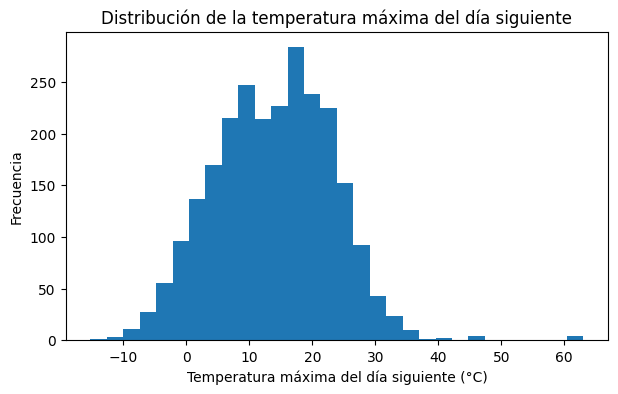

In [22]:
# Visualizamos la distribución de la temperatura máxima del día siguiente
plt.figure(figsize=(7, 4))
plt.hist(df["temp_max_manana"].dropna(), bins=30)

plt.xlabel("Temperatura máxima del día siguiente (°C)")
plt.ylabel("Frecuencia")
plt.title("Distribución de la temperatura máxima del día siguiente")

plt.show()

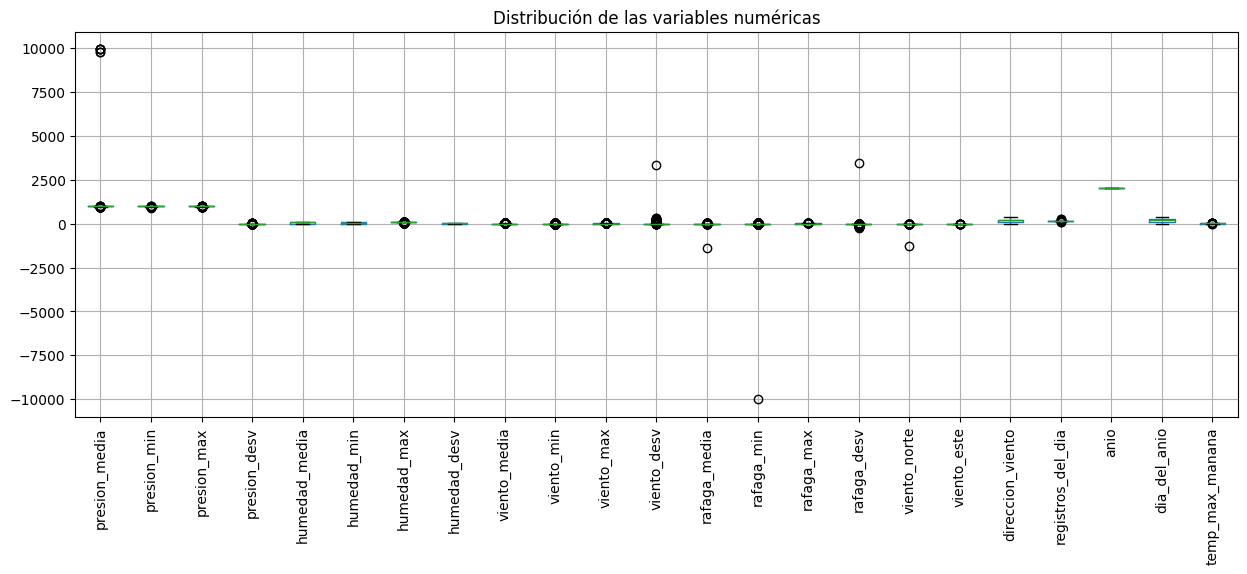

In [23]:
# Visualizamos posibles valores atípicos en las variables numéricas
columnas_numericas = df.select_dtypes(include=np.number).columns

df[columnas_numericas].boxplot(
    figsize=(15, 5),
    rot=90
)

plt.title("Distribución de las variables numéricas")
plt.show()

Revisamos  las variables sospechosas de manera individual

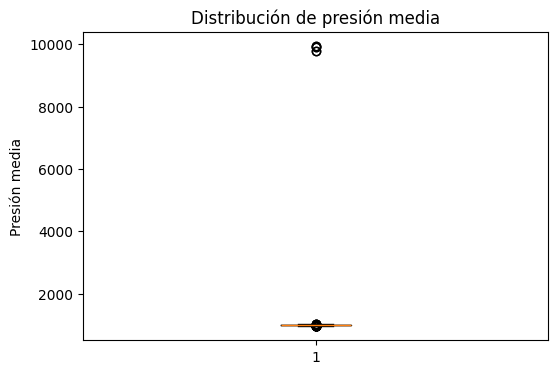

In [24]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["presion_media"].dropna())
plt.ylabel("Presión media")
plt.title("Distribución de presión media")
plt.show()

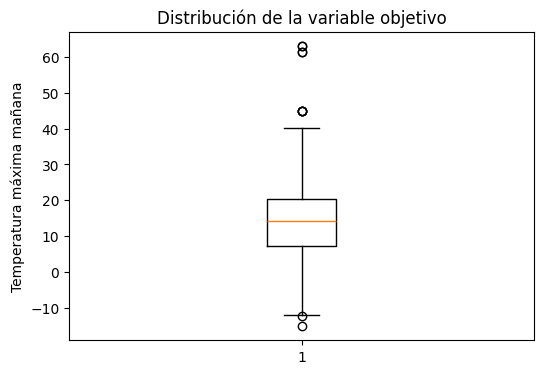

In [25]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["temp_max_manana"].dropna())
plt.ylabel("Temperatura máxima mañana")
plt.title("Distribución de la variable objetivo")
plt.show()

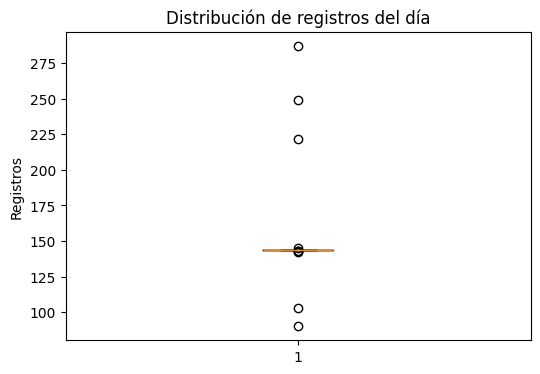

In [26]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["registros_del_dia"].dropna())
plt.ylabel("Registros")
plt.title("Distribución de registros del día")
plt.show()

In [27]:
#Revisamos valores de humedad minima que se encuentren fuera del rango ideal
df[
    (df["humedad_min"]<0) | (df["humedad_min"]>100)
].count().sum()

np.int64(604)

In [28]:
# Revisamos valores de dirección del viento fuera del rango esperado
df[
    (df["direccion_viento"] < 0) |
    (df["direccion_viento"] > 360)
].count().sum()

np.int64(0)

In [29]:
#Revisamos la distribución de la cantidad de registros disponibles por día
df["registros_del_dia"].describe()

count    2499.000000
mean      144.090836
std         4.107365
min        90.000000
25%       144.000000
50%       144.000000
75%       144.000000
max       287.000000
Name: registros_del_dia, dtype: float64

In [30]:
#Identificamos días con una cantidad superior a 144 registros( lo esperado)
df[df["registros_del_dia"]>144][["fecha","registros_del_dia"]]


,fecha,registros_del_dia
546,2010-07-01,287.0
547,2010-07-02,145.0
1904,2014-03-20,222.0
1905,2014-03-21,249.0


In [31]:
#Calculamos la correlación de las variables númericas con la variable objetivo

correlaciones=(
    df.select_dtypes(include=np.number).corr()["temp_max_manana"].sort_values(ascending=False)
)

correlaciones

temp_max_manana      1.000000
humedad_desv         0.571459
dia_del_anio         0.165812
presion_min          0.141860
anio                 0.092718
presion_max          0.070861
viento_desv          0.040129
viento_max           0.031348
rafaga_max           0.030527
registros_del_dia    0.025923
viento_este          0.015941
direccion_viento     0.007824
rafaga_desv         -0.007027
rafaga_min          -0.019087
viento_norte        -0.020881
rafaga_media        -0.024158
presion_media       -0.032249
viento_media        -0.035994
viento_min          -0.039749
humedad_media       -0.098139
humedad_max         -0.155211
presion_desv        -0.199890
humedad_min         -0.203226
Name: temp_max_manana, dtype: float64

In [32]:
# Seleccionamos las variables con mayor correlación absoluta con la variable objetivo
top_variables = (
    correlaciones
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

corr_top = df[top_variables].corr()

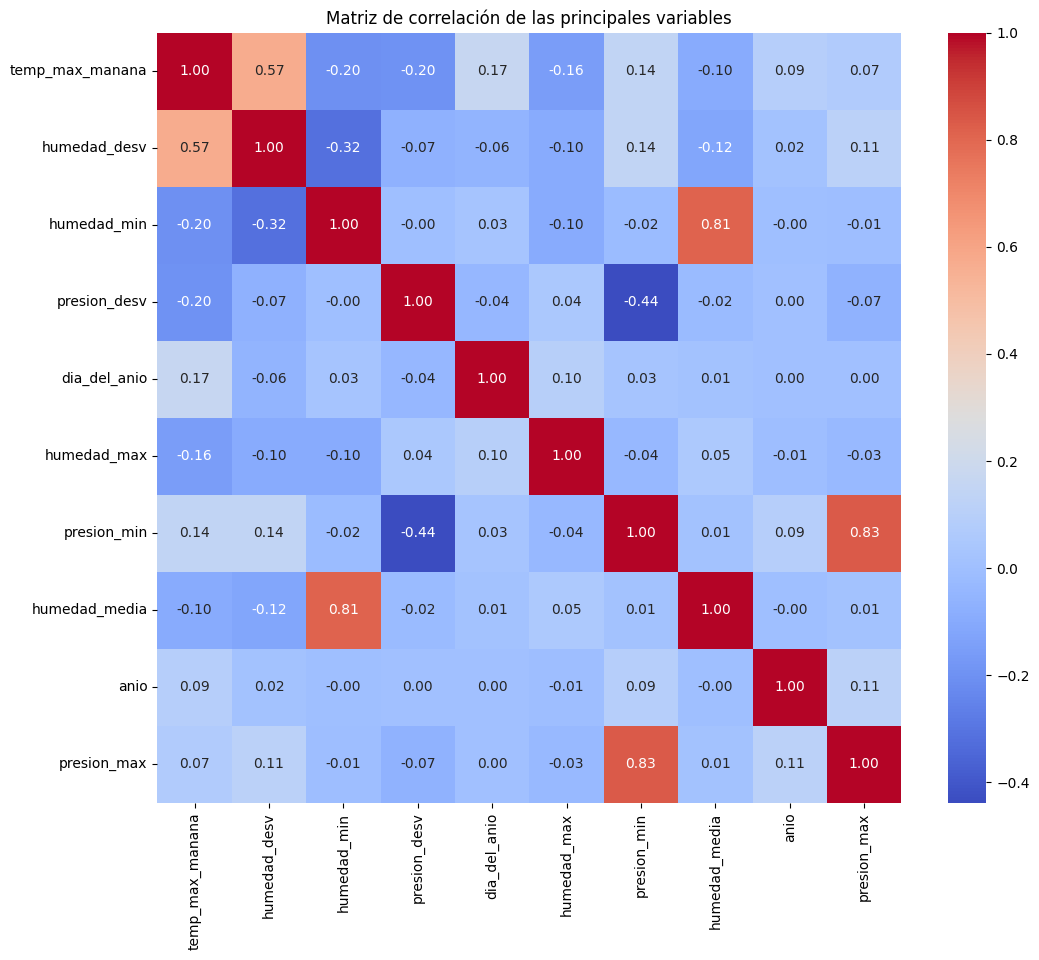

In [33]:
import seaborn as sns

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_top,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de las principales variables")
plt.show()

### Hallazgos de la exploración

La exploración permitió identificar valores faltantes en diferentes variables y en registros duplicados, se encintraron inconsistencias en la representación de variables como "esatcion_anio", "mes" y "sector_viento".
La variables temporales presentan redundancia en la información, dado que algunas vienen directamente de fecha
Finalmente, se encontró que algunas variables numericas presentan valores atípicos o fuera de los rangos, por lo que estos casos deben ser considerados en la preparación de datos

# Preparación de los datos

In [34]:
# Creamos una copia para realizar la preparación de los datos
df_modelo = df.copy()

In [35]:
# Eliminamos registros sin valor en la variable objetivo
df_modelo = df_modelo.dropna(subset=["temp_max_manana"])

df_modelo.shape

(2481, 27)

In [36]:
# Eliminamos registros completamente duplicados
df_modelo = df_modelo.drop_duplicates()

df_modelo.shape

(2477, 27)

In [37]:
#Comprobamos la no existencia de duplicados
df_modelo.duplicated().sum()

np.int64(0)

In [38]:
# Separamos las variables predictoras y la variable objetivo
X = df_modelo.drop(columns=["temp_max_manana"])
y = df_modelo["temp_max_manana"]

print("X:", X.shape)
print("y:", y.shape)

X: (2477, 26)
y: (2477,)


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Test:", X_test.shape)

Entrenamiento: (1857, 26)
Test: (620, 26)


Se reservó el 25% de los datos para evaluación y se utilizó "random_state=42" , de acuerdo con las condiciones establecidas para el laboratorio.

## Modelo 1 - Variables numéricas

Como primera estrategia se construirá un modelo utilizando únicamente las variables numéricas. Las variables categóricas y la fecha se excluyen inicialmente debido a las inconsistencias identificadas durante la exploración. Los valores faltantes serán imputados mediante la mediana dentro de un pipeline.

In [40]:
# Seleccionamos variables numéricas
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()

columnas_numericas

['presion_media',
 'presion_min',
 'presion_max',
 'presion_desv',
 'humedad_media',
 'humedad_min',
 'humedad_max',
 'humedad_desv',
 'viento_media',
 'viento_min',
 'viento_max',
 'viento_desv',
 'rafaga_media',
 'rafaga_min',
 'rafaga_max',
 'rafaga_desv',
 'viento_norte',
 'viento_este',
 'direccion_viento',
 'registros_del_dia',
 'anio',
 'dia_del_anio']

In [41]:
pipeline_modelo_1 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression())
])
pipeline_modelo_1.fit(
    X_train[columnas_numericas],
    y_train
)

Pipeline(steps=[('imputacion', SimpleImputer(strategy='median')),
                ('regresion', LinearRegression())])

In [42]:
#Realizamos predicciones del Modelo 1
pred_modelo_1 = pipeline_modelo_1.predict(
    X_test[columnas_numericas]
)

In [43]:
rmse_1 = np.sqrt(mean_squared_error(y_test, pred_modelo_1))
mae_1 = mean_absolute_error(y_test, pred_modelo_1)
r2_1 = r2_score(y_test, pred_modelo_1)

print("RMSE:", rmse_1)
print("MAE:", mae_1)
print("R²:", r2_1)

RMSE: 7.148230847941255
MAE: 5.645431841020078
R²: 0.4033466172550345


In [44]:
#Comparamos prediccion vs valores reales
comparacion_1 = pd.DataFrame({
    "Real": y_test,
    "Predicción": pred_modelo_1
})

comparacion_1.head(10)

,Real,Predicción
1826,7.26,13.027488
269,17.49,20.215004
2156,2.93,12.658935
1044,7.68,12.829268
61,10.26,16.150026
2511,15.65,12.950670
2168,3.13,10.214494
1174,16.06,21.834388
970,15.59,21.799019
1144,3.98,8.957255


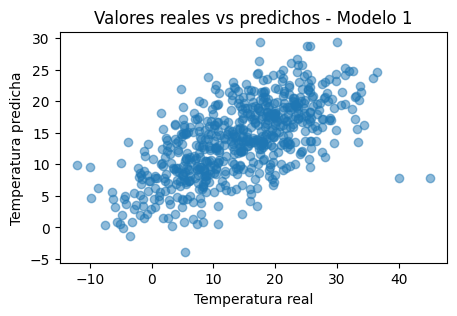

In [45]:
#Graficamos
plt.figure(figsize=(5, 3))

plt.scatter(y_test, pred_modelo_1, alpha=0.5)

plt.xlabel("Temperatura real")
plt.ylabel("Temperatura predicha")
plt.title("Valores reales vs predichos - Modelo 1")

plt.show()

In [46]:
#Guardamos el resultado
resultados = []

resultados.append({
    "Modelo": "Modelo 1 - Variables numéricas",
    "RMSE": rmse_1,
    "MAE": mae_1,
    "R2": r2_1
})

pd.DataFrame(resultados)

,Modelo,RMSE,MAE,R2
0,Modelo 1 - Variables numéricas,7.148231,5.645432,0.403347


## Modelo 2- Ingeniería de características temporales

En la segunda estrategia se incorpora ingeniería de características a partir de "fecha". Debido a las inconsistencias encontradas en la variable "mes", la información temporal se obtiene directamente de la fecha registrada. Además, se incorpora una representación cíclica del momento del año para permitir que el modelo represente mejor la estacionalidad

In [47]:
#Hacemos copias
X_train_2 = X_train.copy()
X_test_2 = X_test.copy()

In [48]:
#Nos aseguramos de que fecha sea datetime
X_train_2["fecha"] = pd.to_datetime(X_train_2["fecha"])
X_test_2["fecha"] = pd.to_datetime(X_test_2["fecha"])

#Creamos el mes correcto
X_train_2["mes_fecha"] = X_train_2["fecha"].dt.month
X_test_2["mes_fecha"] = X_test_2["fecha"].dt.month

#Creamos una representación del día del año
X_train_2["dia_sin"] = np.sin(
    2 * np.pi * X_train_2["fecha"].dt.dayofyear / 365.25
)

X_train_2["dia_cos"] = np.cos(
    2 * np.pi * X_train_2["fecha"].dt.dayofyear / 365.25
)

X_test_2["dia_sin"] = np.sin(
    2 * np.pi * X_test_2["fecha"].dt.dayofyear / 365.25
)

X_test_2["dia_cos"] = np.cos(
    2 * np.pi * X_test_2["fecha"].dt.dayofyear / 365.25
)

In [49]:
# Eliminamos columnas categóricas inconsistentes
columnas_eliminar_2 = [
    "fecha",
    "mes",
    "estacion_anio",
    "sector_viento"
]

X_train_2 = X_train_2.drop(columns=columnas_eliminar_2, errors="ignore")
X_test_2 = X_test_2.drop(columns=columnas_eliminar_2, errors="ignore")

# Verificamos que solo queden variables numéricas
X_train_2.dtypes

presion_media        float64
presion_min          float64
presion_max          float64
presion_desv         float64
humedad_media        float64
humedad_min          float64
humedad_max          float64
humedad_desv         float64
viento_media         float64
viento_min           float64
viento_max           float64
viento_desv          float64
rafaga_media         float64
rafaga_min           float64
rafaga_max           float64
rafaga_desv          float64
viento_norte         float64
viento_este          float64
direccion_viento     float64
registros_del_dia    float64
anio                 float64
dia_del_anio         float64
mes_fecha            float64
dia_sin              float64
dia_cos              float64
dtype: object

In [50]:
X_train_2.select_dtypes(exclude=np.number).columns

Index([], dtype='object')

In [51]:
#Verificamos que las columnas mes_fecha,dia_sin,dia_cos hayan quedado creadas
X_train_2.columns

Index(['presion_media', 'presion_min', 'presion_max', 'presion_desv',
       'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
       'viento_media', 'viento_min', 'viento_max', 'viento_desv',
       'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
       'viento_norte', 'viento_este', 'direccion_viento', 'registros_del_dia',
       'anio', 'dia_del_anio', 'mes_fecha', 'dia_sin', 'dia_cos'],
      dtype='object')

In [52]:
X_train_2.columns

Index(['presion_media', 'presion_min', 'presion_max', 'presion_desv',
       'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
       'viento_media', 'viento_min', 'viento_max', 'viento_desv',
       'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
       'viento_norte', 'viento_este', 'direccion_viento', 'registros_del_dia',
       'anio', 'dia_del_anio', 'mes_fecha', 'dia_sin', 'dia_cos'],
      dtype='object')

In [53]:
#Creamos Pipeline Módulo 2
pipeline_modelo_2 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression())
])

#Entrenamos
pipeline_modelo_2.fit(
    X_train_2,
    y_train
)

#Predecimos
pred_modelo_2 = pipeline_modelo_2.predict(
    X_test_2
)


In [54]:
#Evaluamos
rmse_2 = np.sqrt(mean_squared_error(y_test, pred_modelo_2))
mae_2 = mean_absolute_error(y_test, pred_modelo_2)
r2_2 = r2_score(y_test, pred_modelo_2)

print("RMSE:", rmse_2)
print("MAE:", mae_2)
print("R²:", r2_2)

RMSE: 4.895623619211338
MAE: 3.5912366056472336
R²: 0.7201398830314601


In [55]:
#Agregamos
resultados.append({
    "Modelo": "Modelo 2 - Ingeniería temporal",
    "RMSE": rmse_2,
    "MAE": mae_2,
    "R2": r2_2
})

In [56]:
#Comparamos
tabla_resultados = pd.DataFrame(resultados)

tabla_resultados

,Modelo,RMSE,MAE,R2
0,Modelo 1 - Variables numéricas,7.148231,5.645432,0.403347
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.720140


## Modelo 3 - Tratamiento de valores inconsistentes

 Como tercera estrategia se parte de la ingenieria temporal del modelo 2 y se incorpora un tratamiento adicional de valores inconsistentes detectados durante la exploración. Los valores encontradosfuera de los rangos físicamente posibles se reemplazan por valores faltantes para que posteriormente sean imputados mediante la mediana dentro del pipeline

In [57]:
# Creamos nuevas copias para el tercer modelo
X_train_3 = X_train.copy()
X_test_3 = X_test.copy()

#Convertimos fecha
X_train_3["fecha"] = pd.to_datetime(X_train_3["fecha"], errors="coerce")
X_test_3["fecha"] = pd.to_datetime(X_test_3["fecha"], errors="coerce")

#Ingeniería de características temporales
X_train_3["mes_fecha"] = X_train_3["fecha"].dt.month
X_test_3["mes_fecha"] = X_test_3["fecha"].dt.month

X_train_3["dia_sin"] = np.sin(
    2 * np.pi * X_train_3["fecha"].dt.dayofyear / 365.25
)

X_train_3["dia_cos"] = np.cos(
    2 * np.pi * X_train_3["fecha"].dt.dayofyear / 365.25
)

X_test_3["dia_sin"] = np.sin(
    2 * np.pi * X_test_3["fecha"].dt.dayofyear / 365.25
)

X_test_3["dia_cos"] = np.cos(
    2 * np.pi * X_test_3["fecha"].dt.dayofyear / 365.25
)


Tratamos valores físicamente inconsistentes, vamos a convertie en NaN aquellos valores que claramente violan una restricción lógica

In [58]:
#Humedad: entre 0 y 100
columnas_humedad = [
    "humedad_media",
    "humedad_min",
    "humedad_max"
]

for columna in columnas_humedad:
    X_train_3.loc[
        (X_train_3[columna] < 0) | (X_train_3[columna] > 100),
        columna
    ] = np.nan

    X_test_3.loc[
        (X_test_3[columna] < 0) | (X_test_3[columna] > 100),
        columna
    ] = np.nan

#Dirección del viento entre 0 y 360 grados
X_train_3.loc[
    (X_train_3["direccion_viento"] < 0) |
    (X_train_3["direccion_viento"] > 360),
    "direccion_viento"
] = np.nan

X_test_3.loc[
    (X_test_3["direccion_viento"] < 0) |
    (X_test_3["direccion_viento"] > 360),
    "direccion_viento"
] = np.nan


#Cantidad de registros diarios
X_train_3.loc[
    (X_train_3["registros_del_dia"] <= 0) |
    (X_train_3["registros_del_dia"] > 144),
    "registros_del_dia"
] = np.nan

X_test_3.loc[
    (X_test_3["registros_del_dia"] <= 0) |
    (X_test_3["registros_del_dia"] > 144),
    "registros_del_dia"
] = np.nan

#Variables que no deberían ser negativas
columnas_no_negativas = [
    "viento_media",
    "viento_min",
    "viento_max",
    "viento_desv",
    "rafaga_media",
    "rafaga_min",
    "rafaga_max",
    "rafaga_desv",
    "presion_desv",
    "humedad_desv"
]

for columna in columnas_no_negativas:
    X_train_3.loc[X_train_3[columna] < 0, columna] = np.nan
    X_test_3.loc[X_test_3[columna] < 0, columna] = np.nan

In [59]:
#Eliminamos variables categóricas inconsistentes
columnas_eliminar_3 = [
    "fecha",
    "mes",
    "estacion_anio",
    "sector_viento"
]

X_train_3 = X_train_3.drop(
    columns=columnas_eliminar_3,
    errors="ignore"
)

X_test_3 = X_test_3.drop(
    columns=columnas_eliminar_3,
    errors="ignore"
)

In [60]:
#Comprobación
X_train_3.select_dtypes(exclude=np.number).columns

Index([], dtype='object')

# Entrenamiento del modelo 3

In [61]:
pipeline_modelo_3 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression())
])

In [62]:
pipeline_modelo_3.fit(
    X_train_3,
    y_train
)

Pipeline(steps=[('imputacion', SimpleImputer(strategy='median')),
                ('regresion', LinearRegression())])

In [63]:
#Predecimos
pred_modelo_3 = pipeline_modelo_3.predict(
    X_test_3
)

In [64]:
#Evaluamos
rmse_3 = np.sqrt(
    mean_squared_error(y_test, pred_modelo_3)
)

mae_3 = mean_absolute_error(
    y_test,
    pred_modelo_3
)

r2_3 = r2_score(
    y_test,
    pred_modelo_3
)

print("RMSE:", rmse_3)
print("MAE:", mae_3)
print("R²:", r2_3)

RMSE: 4.867908302269602
MAE: 3.5613968811297876
R²: 0.7232996260897626


In [65]:
#Agregamos los resultados obtenidos
resultados.append({
    "Modelo": "Modelo 3 - Limpieza e ingeniería temporal",
    "RMSE": rmse_3,
    "MAE": mae_3,
    "R2": r2_3
})

## Comparación entre los tres modelos

In [66]:
tabla_resultados = pd.DataFrame(resultados)

tabla_resultados = tabla_resultados.sort_values(
    by="RMSE"
).reset_index(drop=True)

tabla_resultados

,Modelo,RMSE,MAE,R2
0,Modelo 3 - Limpieza e ingeniería temporal,4.867908,3.561397,0.723300
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.720140
2,Modelo 1 - Variables numéricas,7.148231,5.645432,0.403347


# Creamos la tabla definitiva con los 2 mejores

In [67]:
dos_mejores_modelos = tabla_resultados.head(2)

dos_mejores_modelos

,Modelo,RMSE,MAE,R2
0,Modelo 3 - Limpieza e ingeniería temporal,4.867908,3.561397,0.72330
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.72014


### Comparación de modelos

Se evaluaron tres estrategias de preparación utilizando regresión lineal. Para la comparación final se seleccionan los dos modelos con menor RMSE sobre el conjunto de prueba. Como métricas complementarias también se consideran el MAE y el R².

## Gráfico comparativo de RMSE

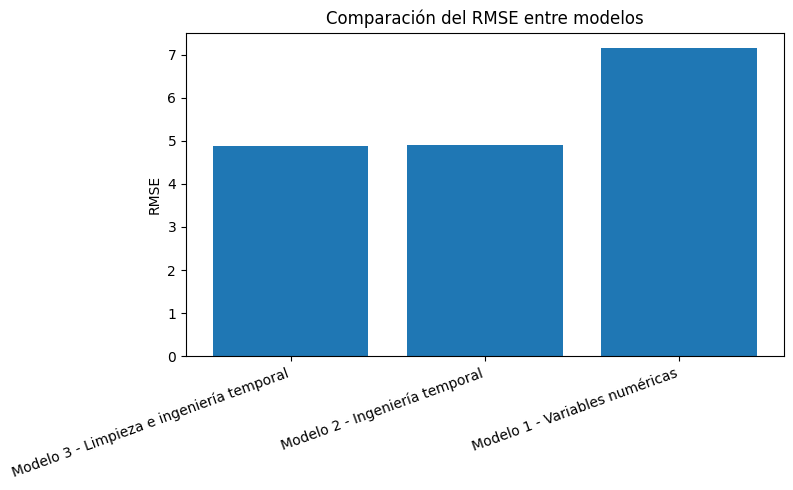

In [68]:
plt.figure(figsize=(8, 5))

plt.bar(
    tabla_resultados["Modelo"],
    tabla_resultados["RMSE"]
)

plt.ylabel("RMSE")
plt.title("Comparación del RMSE entre modelos")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

## Elección del mejor modelo


In [69]:
mejor_resultado = tabla_resultados.iloc[0]

print("Mejor modelo:", mejor_resultado["Modelo"])
print("RMSE:", mejor_resultado["RMSE"])
print("MAE:", mejor_resultado["MAE"])
print("R²:", mejor_resultado["R2"])

Mejor modelo: Modelo 3 - Limpieza e ingeniería temporal
RMSE: 4.867908302269602
MAE: 3.5613968811297876
R²: 0.7232996260897626


### Selección del mejor modelo

De acuerdo con los resultados obtenidos sobre el conjunto de prueba, el modelo con mejor desempeño fue el Modelo 3, al obtener el menor RMSE. Adicionalmente, se tuvieron en cuenta los valores de MAE y R² para complementar la evaluación del desempeño predictivo.

In [70]:
mejor_modelo = pipeline_modelo_3
mejor_X_train = X_train_3
mejor_X_test = X_test_3
mejor_pred = pred_modelo_3

# Evaluación cualitativa: importancia de variables

Para saber qué variables importan más, el problema es que están en escalas súper distintas (por ejemplo presion_media anda en miles y dia_sin anda entre -1 y 1), entonces comparar los coeficientes del Modelo 3 tal cual no es justo.

Por eso entrenamos otra vez el mismo pipeline pero agregando un escalado antes de la regresión. Esto no cambia las predicciones ni el RMSE (en una regresión lineal, escalar las variables no afecta el resultado), lo único que cambia es que ahora sí podemos comparar los coeficientes entre ellos y usarlos como medida de importancia relativa.

In [71]:
# Reconstruimos el pipeline ganador agregando escalado, solo para interpretar coeficientes
pipeline_mejor_escalado = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("regresion", LinearRegression())
])

pipeline_mejor_escalado.fit(mejor_X_train, y_train)

pred_mejor_escalado = pipeline_mejor_escalado.predict(mejor_X_test)

rmse_escalado = np.sqrt(mean_squared_error(y_test, pred_mejor_escalado))

print("RMSE modelo original (sin escalado):", rmse_3)
print("RMSE con escalado (solo para interpretar coeficientes):", rmse_escalado)

RMSE modelo original (sin escalado): 4.867908302269602
RMSE con escalado (solo para interpretar coeficientes): 4.867908302269606


In [72]:
# Extraemos los coeficientes estandarizados y los ordenamos por magnitud
tabla_coeficientes = pd.DataFrame({
    "Variable": mejor_X_train.columns,
    "Coeficiente_estandarizado": pipeline_mejor_escalado.named_steps["regresion"].coef_
})

tabla_coeficientes["Coeficiente_abs"] = tabla_coeficientes["Coeficiente_estandarizado"].abs()
tabla_coeficientes = tabla_coeficientes.sort_values(
    "Coeficiente_abs", ascending=False
).reset_index(drop=True)

print("Intercepto:", pipeline_mejor_escalado.named_steps["regresion"].intercept_)
tabla_coeficientes

Intercepto: 13.753685371544774


,Variable,Coeficiente_estandarizado,Coeficiente_abs
0,rafaga_desv,-42.397179,42.397179
1,viento_norte,-42.085071,42.085071
2,dia_cos,-6.319035,6.319035
3,humedad_desv,1.781197,1.781197
4,dia_sin,-1.695563,1.695563
5,dia_del_anio,0.911234,0.911234
6,mes_fecha,-0.788550,0.788550
7,anio,0.772585,0.772585
8,direccion_viento,-0.657142,0.657142
9,presion_max,0.532947,0.532947


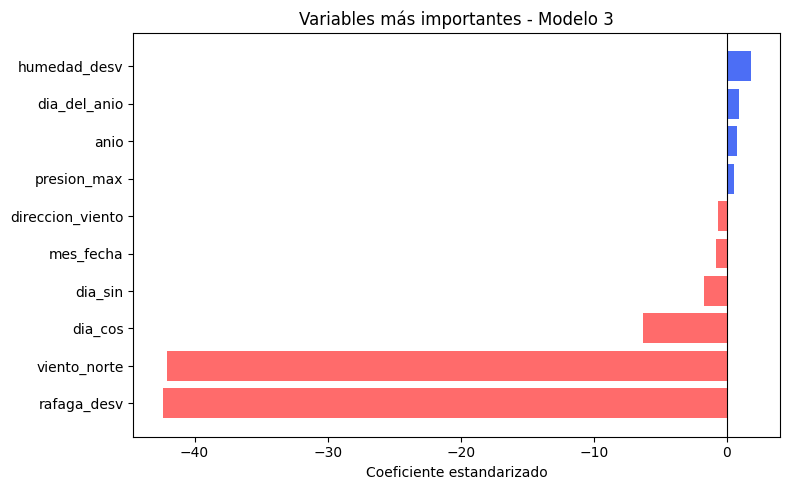

In [73]:
# Graficamos las 10 variables con mayor peso en la predicción
top_coeficientes = tabla_coeficientes.head(10).sort_values("Coeficiente_estandarizado")

plt.figure(figsize=(8, 5))
colores = ["#FF6B6B" if v < 0 else "#4C6EF5" for v in top_coeficientes["Coeficiente_estandarizado"]]
plt.barh(top_coeficientes["Variable"], top_coeficientes["Coeficiente_estandarizado"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente estandarizado")
plt.title("Variables más importantes - Modelo 3")
plt.tight_layout()
plt.show()

Primero comprobamos que agregar el escalado no cambió nada del desempeño: el RMSE con y sin el escalado da prácticamente igual (4.867908 en los dos casos), como era de esperarse en una regresión lineal. Los coeficientes estandarizados más grandes son rafaga_desv (-42.40) y viento_norte (-42.09), bastante más grandes que dia_cos (-6.32), humedad_desv (+1.78) y dia_sin (-1.70).

Pero ojo, que rafaga_desv y viento_norte salgan tan grandes no significa que sean las variables más importantes. Más adelante, cuando revisamos la multicolinealidad con el VIF, nos dimos cuenta de que el Modelo 3 tiene un montón de variables repetidas entre sí (por ejemplo presion_media, presion_min y presion_max, o humedad_media, humedad_min y humedad_max, o las cuatro formas distintas de representar la estacionalidad: dia_del_anio, mes_fecha, dia_sin y dia_cos). Cuando hay tanta multicolinealidad los coeficientes se vuelven inestables y se pueden inflar sin que eso signifique que esa variable de verdad importa tanto, aunque el modelo en general siga prediciendo bien. Por eso retomamos esta interpretación con más cuidado después de ver el VIF.

# Validación de los supuestos de la regresión lineal

Antes de confiar en los coeficientes como medida de importancia, revisamos si el Modelo 3 cumple los supuestos típicos de la regresión lineal: linealidad, normalidad de los residuales, homocedasticidad, independencia y que no haya multicolinealidad muy fuerte. Los residuales los calculamos sobre el conjunto de entrenamiento, que es donde se ajustó el modelo.

In [74]:
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculamos los residuales del Modelo 3 sobre el conjunto de entrenamiento
pred_train_3 = mejor_modelo.predict(mejor_X_train)
residuales = y_train.values - pred_train_3

print("Cantidad de residuales:", residuales.shape[0])
print("Media de los residuales:", residuales.mean())

Cantidad de residuales: 1857
Media de los residuales: -1.1199561591652199e-14


### Linealidad y homocedasticidad

Graficamos los residuales contra los valores ajustados. Si la linealidad se cumple no debería verse una curva, y si la varianza de los residuales se mantiene más o menos igual a lo largo del eje X, se cumple homocedasticidad (si se ve como un embudo, hay heterocedasticidad).

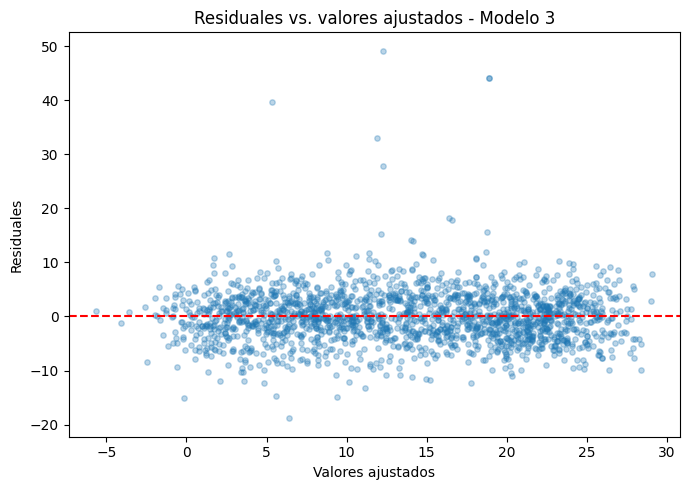

In [75]:
plt.figure(figsize=(7, 5))
plt.scatter(pred_train_3, residuales, alpha=0.3, s=15)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuales")
plt.title("Residuales vs. valores ajustados - Modelo 3")
plt.tight_layout()
plt.show()

In [76]:
# Prueba de Breusch-Pagan para homocedasticidad (H0: varianza constante)
imputador_bp = SimpleImputer(strategy="median")
X_train_3_imputado = pd.DataFrame(
    imputador_bp.fit_transform(mejor_X_train),
    columns=mejor_X_train.columns
)

X_train_3_const = sm.add_constant(X_train_3_imputado)
bp_stat, bp_p, bp_f, bp_f_p = het_breuschpagan(residuales, X_train_3_const)

print(f"Breusch-Pagan: estadístico LM = {bp_stat:.4f}, p-valor = {bp_p:.4g}")

Breusch-Pagan: estadístico LM = 65.9156, p-valor = 1.527e-05


### Normalidad de los residuales

Miramos un histograma, un gráfico Q-Q y la prueba de Shapiro-Wilk (la hipótesis nula es que los residuales sí vienen de una normal). Con una muestra tan grande, Shapiro-Wilk se pone muy sensible y rechaza la normalidad por cualquier cosita, así que el histograma y el Q-Q son la evidencia que realmente importa.

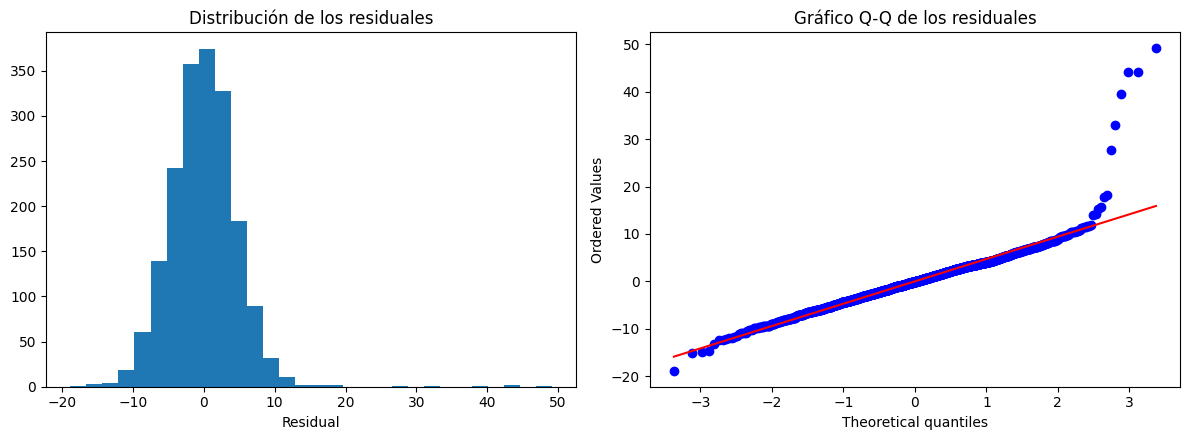

Shapiro-Wilk: estadístico = 0.9037, p-valor = 1.108e-32


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(residuales, bins=30)
axes[0].set_title("Distribución de los residuales")
axes[0].set_xlabel("Residual")

stats.probplot(residuales, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de los residuales")

plt.tight_layout()
plt.show()

muestra_shapiro = residuales if len(residuales) <= 5000 else np.random.choice(residuales, 5000, replace=False)
shapiro_stat, shapiro_p = stats.shapiro(muestra_shapiro)
print(f"Shapiro-Wilk: estadístico = {shapiro_stat:.4f}, p-valor = {shapiro_p:.4g}")

### Independencia de los residuales

Calculamos el estadístico de Durbin-Watson (si da cerca de 2, no hay autocorrelación entre residuales seguidos). Aclaramos que las filas de entrenamiento quedaron desordenadas después del train_test_split, así que esto es más un chequeo formal que una prueba real de independencia en el tiempo.

In [78]:
dw_stat = durbin_watson(residuales)
print(f"Durbin-Watson: {dw_stat:.4f}")

Durbin-Watson: 2.0196


### Multicolinealidad

Calculamos el VIF (factor de inflación de varianza) para cada variable sobre los datos de entrenamiento ya imputados. Como referencia, un VIF arriba de 10 (algunos dicen que arriba de 5) ya se considera multicolinealidad problemática con las demás variables del modelo.

In [79]:
with np.errstate(divide="ignore", invalid="ignore"):
    tabla_vif = pd.DataFrame({
        "Variable": X_train_3_imputado.columns,
        "VIF": [
            variance_inflation_factor(X_train_3_imputado.values, i)
            for i in range(X_train_3_imputado.shape[1])
        ]
    }).sort_values("VIF", ascending=False).reset_index(drop=True)

tabla_vif

,Variable,VIF
0,presion_max,70202.967692
1,presion_min,64573.962997
2,anio,28438.434488
3,registros_del_dia,8294.595024
4,rafaga_desv,922.464828
5,viento_norte,912.718044
6,humedad_max,88.252839
7,mes_fecha,76.919673
8,dia_del_anio,60.959028
9,rafaga_media,30.222964


Resumen de cómo le fue al Modelo 3 en cada supuesto:

Linealidad: la nube de residuales contra los ajustados no forma una curva clara, se ve bastante dispersa alrededor de cero. Hay un grupito de residuales bien grandes (hasta +49) entre los 12 y 20°C de valor ajustado, pero no alcanzan a formar un patrón. O sea, se cumple más o menos bien.

Normalidad: Shapiro-Wilk da un p-valor casi cero (1.1x10-32), pero con 1857 datos esa prueba rechaza la normalidad por cualquier cosita. El histograma se ve simétrico y centrado en cero, y en el Q-Q los puntos siguen bastante bien la línea en la parte de en medio, donde se separan es en la cola derecha, con esos mismos residuales grandes que vimos antes. O sea, normalidad más o menos sí, menos en esa cola.

Homocedasticidad: Breusch-Pagan da p=1.5x10-5, o sea que técnicamente sí hay heterocedasticidad. En el gráfico esto se nota más que nada por esos residuales atípicos y por una dispersión un poco mayor en la parte media del rango, no tanto como un embudo bien marcado.

Independencia: Durbin-Watson dio 2.02, prácticamente 2, así que no se ve autocorrelación. Pero como ya dijimos, el split desordena las filas, así que este número no prueba de verdad que no haya correlación en el tiempo.

Multicolinealidad: acá está el problema más grande. El VIF de presion_max (como 70 mil), presion_min (65 mil), anio (28 mil) y registros_del_dia (8 mil) son absurdamente altos, muy por encima del límite de 10. Hasta rafaga_desv (920) y viento_norte (913), que fueron los coeficientes más grandes de la sección anterior, están muy arriba de ese límite. Esto confirma que el Modelo 3 dejó muchas variables repetidas entre sí (las tres de presión, las tres de humedad, y hasta cuatro formas de representar la estacionalidad), y por eso los coeficientes no se pueden tomar al pie de la letra como un ranking de qué variable importa más, aunque el RMSE, MAE y R2 que reportamos sí siguen siendo válidos.

En general el Modelo 3 cumple bien linealidad e independencia, cumple normalidad menos en la cola derecha, tiene heterocedasticidad que sí sale significativa en la prueba, y sobre todo tiene multicolinealidad severa entre varias variables. Esto último es lo más importante a tener en cuenta: no podemos leer los coeficientes de forma literal como el ranking de importancia, algo que retomamos en el análisis de resultados.

# Análisis de resultados

### ¿Cuál fue el valor de los diferentes coeficientes obtenidos en el mejor modelo?

In [80]:
tabla_coeficientes.round(4)

,Variable,Coeficiente_estandarizado,Coeficiente_abs
0,rafaga_desv,-42.3972,42.3972
1,viento_norte,-42.0851,42.0851
2,dia_cos,-6.3190,6.3190
3,humedad_desv,1.7812,1.7812
4,dia_sin,-1.6956,1.6956
5,dia_del_anio,0.9112,0.9112
6,mes_fecha,-0.7885,0.7885
7,anio,0.7726,0.7726
8,direccion_viento,-0.6571,0.6571
9,presion_max,0.5329,0.5329


El intercepto del Modelo 3 (la versión con escalado que usamos solo para poder comparar coeficientes) da 13.75°C. Como las variables están estandarizadas, se pueden comparar los coeficientes directamente por su tamaño, aunque como ya explicamos arriba y confirmamos con el VIF, varios están inflados por la multicolinealidad:

rafaga_desv (-42.40) y viento_norte (-42.09) son, en tamaño, los coeficientes más grandes, pero también son las dos variables con el VIF más alto entre las que quedan en un rango "moderado" (920 y 913), así que su tamaño está distorsionado por lo correlacionadas que están con otras variables y no lo podemos tomar como que de verdad son las más importantes.

dia_cos (-6.32) es el coeficiente más grande entre los que tienen un VIF razonable (1.70), así que este sí es un resultado confiable: la estacionalidad domina la predicción, lo cual tiene sentido para algo tan estacional como la temperatura.

humedad_desv (+1.78) y dia_sin (-1.70) también están entre los coeficientes grandes y confiables: humedad_desv además fue la variable con más correlación individual con el objetivo que encontramos en la exploración (0.57).

El resto de coeficientes (dia_del_anio, mes_fecha, anio, direccion_viento, presion_max, etc.) son menores a 1, o sea que solo hacen ajustes chiquitos sobre la señal principal.

### A partir de la tabla comparativa, ¿cuál modelo ofrece el mejor rendimiento sobre el conjunto test? ¿Qué interpretación puedes darles a los valores obtenidos sobre las métricas de rendimiento?

In [81]:
dos_mejores_modelos

,Modelo,RMSE,MAE,R2
0,Modelo 3 - Limpieza e ingeniería temporal,4.867908,3.561397,0.72330
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.72014


En el conjunto de prueba (25% de los datos, con random_state=42) el que mejor le fue de los tres fue el Modelo 3, el que limpia valores inconsistentes y le agrega la ingeniería temporal: RMSE = 4.87°C, MAE = 3.56°C y R2 = 0.723. Le gana por poquito al Modelo 2 (RMSE = 4.90°C, R2 = 0.720) y le gana bastante más al Modelo 1, que solo usaba las variables numéricas sin nada de ingeniería temporal (RMSE = 7.15°C, R2 = 0.403).

Cómo interpretamos esas métricas:
- El RMSE queda en las mismas unidades que la variable objetivo (°C), y como eleva los errores al cuadrado antes de promediarlos, castiga más los errores grandes. Que el Modelo 3 tenga RMSE=4.87°C quiere decir que en promedio (dándole más peso a los errores grandes) se equivoca por casi 5 grados al predecir la temperatura máxima del día siguiente.
- El MAE (3.56°C) sale menor que el RMSE en los tres modelos, lo cual es normal: que haya diferencia entre los dos indica que hay algunos días donde el error es bastante más grande que el promedio (por ejemplo cuando cambia el clima de golpe), mientras que en la mayoría de los días el error anda como en 3.5 grados.
- El R2 de 0.723 dice que el Modelo 3 explica como el 72% de la variabilidad de la temperatura máxima del día siguiente con las variables que tenemos. El salto tan grande frente al Modelo 1 (R2=0.403) muestra que la ingeniería temporal (usar dia_sin/dia_cos y mes_fecha en vez de depender de la variable mes original, que estaba llena de inconsistencias) es lo que más aporta, y que además el tratamiento de valores raros que se agregó en el Modelo 3 suma una mejora más chiquita pero constante sobre el Modelo 2.
- El 28% de la varianza que ningún modelo logra explicar tiene sentido si pensamos en lo impredecible que puede ser el clima de un día para otro (por ejemplo la llegada repentina de un frente frío), algo que un modelo lineal como este no puede captar del todo.

### ¿Cuáles variables fueron seleccionadas con el modelo seleccionado? A partir de estas, ¿qué interpretación de cara al problema puedes dar? Reflexiona sobre cómo este nuevo conocimiento podría ayudar a tomar decisiones en el contexto del problema.

In [82]:
tabla_coeficientes.head(8).round(4)

,Variable,Coeficiente_estandarizado,Coeficiente_abs
0,rafaga_desv,-42.3972,42.3972
1,viento_norte,-42.0851,42.0851
2,dia_cos,-6.3190,6.3190
3,humedad_desv,1.7812,1.7812
4,dia_sin,-1.6956,1.6956
5,dia_del_anio,0.9112,0.9112
6,mes_fecha,-0.7885,0.7885
7,anio,0.7726,0.7726


Las variables con el coeficiente más grande en el Modelo 3 (top 8) son: rafaga_desv, viento_norte, dia_cos, humedad_desv, dia_sin, dia_del_anio, mes_fecha y anio.

Interpretación para el problema de AlpesPlanck (con la salvedad de la multicolinealidad que ya mencionamos):
- Las variables en las que más confiamos de esta lista son las de estacionalidad (dia_cos, dia_sin, dia_del_anio, mes_fecha): su VIF es bajo o moderado y su efecto tiene sentido físico. Esto confirma que el ciclo anual de temperatura es la señal más sólida para predecir la temperatura máxima del día siguiente, y concuerda con el salto de desempeño que vimos al pasar del Modelo 1 (sin variables temporales) al Modelo 2 (RMSE de 7.15 a 4.90°C).
- humedad_desv (qué tanto varía la humedad en el día) es la segunda señal en la que más confiamos, y ya la habíamos visto en la exploración como la variable con más correlación con el objetivo. Los días con más variabilidad de humedad tienden a tener temperaturas máximas más altas, algo típico de días inestables de verano. Para AlpesPlanck esto importa porque la variabilidad de humedad, junto con la estacionalidad, son señales tempranas de condiciones cálidas y secas que se relacionan con más riesgo de incendio forestal.
- rafaga_desv y viento_norte salieron con los coeficientes más grandes, pero no podemos confiar tanto en ellos por la multicolinealidad que encontramos con el VIF: antes de usar justo esas dos variables para tomar decisiones, habría que repetir el análisis quitando columnas repetidas (por ejemplo quedarse con una sola medida de presión, una de humedad y una sola forma de representar la estacionalidad).
- En general, lo que le queda a AlpesPlanck de este ejercicio es que el ciclo estacional y la variabilidad de humedad son las señales meteorológicas más sólidas para anticipar temperaturas máximas raras, mientras que lo que parece indicar el viento y las ráfagas necesitaría un modelo con menos variables repetidas antes de poder usarse como base para tomar decisiones.

### A partir del contexto y los datos compartidos, ¿cómo representar la regresión lineal de forma matemática? Indique el método utilizado y el proceso para resolverlo.

La regresión lineal múltiple que usamos en el Modelo 3 se representa así:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p + \varepsilon = X\beta + \varepsilon$$

donde y-gorro es la temperatura máxima del día siguiente que predice el modelo, X es la matriz con las variables predictoras (las 25 columnas numéricas de mejor_X_train, ya imputadas), β es el vector de coeficientes (incluyendo el intercepto β0) y ε es el error que el modelo no logra explicar.

LinearRegression de sklearn no usa descenso de gradiente: resuelve el problema de mínimos cuadrados ordinarios (OLS) de forma cerrada, buscando el β que minimiza la suma de los residuales al cuadrado:

$$\hat{\beta} = \arg\min_{\beta} \; \lVert y - X\beta \rVert^2$$

Este problema tiene una solución exacta con la ecuación normal:

$$\hat{\beta} = (X^\top X)^{-1} X^\top y$$

En la práctica, sklearn no invierte literalmente esa matriz por temas de estabilidad numérica (puede ser casi singular cuando hay variables muy correlacionadas entre sí, como vimos en la sección de multicolinealidad), en cambio calcula la solución con una descomposición en valores singulares (SVD) de X, usando lstsq de scipy. Este método cerrado tiene sentido acá porque el dataset es chico (miles de filas, un par de decenas de columnas), entonces calcular la solución exacta sale barato y no hay que estar ajustando hiperparámetros de convergencia (tasa de aprendizaje, número de iteraciones) como sí tocaría con un método iterativo (por ejemplo SGDRegressor), que solo conviene cuando el volumen de datos es mucho más grande o el aprendizaje es en flujo continuo.

### En el ciclo de machine learning ¿Qué tipos de sesgo podría afectar los resultados y por qué? Describe dos tipos de sesgo.

1. Sesgo de calidad de los datos (data quality / measurement bias). En la exploración encontramos errores de captura bastante sistemáticos: valores de presion_media de hasta como 9939 mbar (un error de coma decimal, porque la presión real anda entre 950 y 1015 mbar), 604 registros con humedad_min fuera del rango físico [0, 100]%, y las variables categóricas (estacion_anio, mes, sector_viento) mezclando idiomas, mayúsculas y minúsculas, y errores de tipeo. En el Modelo 3 esos valores raros se pasaron a NaN para imputarlos con la mediana, y las categóricas inconsistentes simplemente las sacamos como predictoras. Cualquiera de esas decisiones de limpieza (qué umbral usar para considerar un valor "imposible", imputar con la mediana en vez de otra cosa) es una decisión nuestra que puede meter sesgo: si el umbral es muy estricto podemos estar botando datos válidos, y si es muy suave pueden quedar errores sin corregir, y eso afecta qué tan representativos quedan los datos con los que aprende el modelo.

2. Sesgo temporal o de cambio de distribución (temporal / distribution shift bias). El archivo de entrenamiento cubre del 2009 al 2015, mientras que el archivo de prueba no etiquetado es todo del 2016, un año que el modelo nunca ve mientras entrena, y que además llega con un formato de fecha distinto (día.mes.año en vez de año-mes-día), otra señal de que los dos archivos no salieron exactamente del mismo proceso. Además, el train_test_split con random_state=42 mezcla las filas al azar en vez de respetar el orden en el tiempo, entonces el conjunto de prueba que usamos en la sección 5 no nos dice qué tan bien generaliza el modelo a un año que no vio, solo a días al azar dentro del mismo rango de años de entrenamiento. Si hay tendencias climáticas de largo plazo (calentamiento poco a poco, fases de El Niño o La Niña) que la variable anio no logra capturar bien de forma lineal, el desempeño real del modelo sobre el 2016 podría ser distinto (mejor o peor) al RMSE de 4.87°C que reportamos sobre el conjunto de prueba interno.

# Uso de herramientas de IA generativa

Se usó Claude Code como apoyo para terminar la parte final del laboratorio, a partir de lo que el equipo ya había hecho (exploración, preparación y los tres modelos ya entrenados y comparados): armar la tabla de coeficientes estandarizados para medir importancia de variables, validar los supuestos de la regresión lineal (linealidad, normalidad, homocedasticidad, independencia y multicolinealidad, siguiendo lo que vimos en la práctica P4 del curso), mejorar la redacción de las respuestas de la sección de análisis de resultados con base en los números que salieron al correr el notebook, y obtener el html

Prompts que usamos (los más importantes):

- Agrega una versión del pipeline ganador con escalado para poder comparar los coeficientes de forma justa entre variables con distintas unidades, sin que cambien las predicciones del modelo
- Valida los supuestos de la regresión lineal del mejor modelo (linealidad, normalidad, homocedasticidad, independencia, multicolinealidad) usando statsmodels y scipy
- Mejora la redacción y/o el contenido de los párrafos de analisis

Qué tan bueno fue lo que generó:
- Lo que más nos sirvió fue que identificara que el archivo de prueba usa un formato de fecha distinto al de entrenamiento (día.mes.año contra año-mes-día) y que es todo del año 2016, eso lo verificamos directamente contra los datos antes de usarlo, y evitó que metiéramos un error silencioso al generar las predicciones finales
- Revisamos que el paso de escalado que se agregó para interpretar los coeficientes no cambiara el RMSE del Modelo 3 que ya teníamos reportado (lo comparamos directamente contra el resultado original), para estar seguros de que la interpretación de importancia de variables fuera coherente con el modelo que en verdad seleccionamos

Qué hicimos nosotros: nosotros decidimos y armamos, sin ayuda de IA, las estrategias de preparación de datos de los tres modelos (qué variables usar, la ingeniería temporal cíclica a partir de la fecha, y las reglas para tratar los valores físicamente inconsistentes), entrenamos los pipelines y sacamos la tabla comparativa de RMSE/MAE/R2 que define cuál modelo gana. Con eso ya armado, revisamos y validamos las interpretaciones que se generaron para la sección de análisis de resultados contra los números reales que salieron al correr el notebook, y decidimos qué parte de la exploración (por ejemplo el desfase de años entre 2009-2015 y 2016) era relevante para la pregunta de sesgos. Por último pusimos a prueba el modelo con datos nuevos, para que predijera la variable objetivo


# Uso del modelo: predicciones sobre datos no etiquetados

Al archivo Datos Test Lab 1.csv (el no etiquetado) le aplicamos la misma preparación que usamos en el Modelo 3: ingeniería temporal a partir de la fecha y el tratamiento de valores físicamente inconsistentes. Algo importante que encontramos es que el formato de fecha del archivo de prueba es día.mes.año (por ejemplo 01.01.2016), distinto al año-mes-día del archivo de entrenamiento, entonces lo interpretamos con el formato correcto para no invertir el día y el mes por error.

Antes de predecir, volvimos a entrenar el pipeline ganador pero esta vez sobre el 100% de los datos etiquetados y limpios

In [83]:
def preparar_modelo_3(df_input, formato_fecha=None):
    """Aplica al dataframe la misma ingeniería temporal y tratamiento de
    valores inconsistentes usados para construir X_train_3/X_test_3."""
    datos = df_input.copy()

    datos["fecha"] = pd.to_datetime(datos["fecha"], format=formato_fecha, errors="coerce")

    datos["mes_fecha"] = datos["fecha"].dt.month
    datos["dia_sin"] = np.sin(2 * np.pi * datos["fecha"].dt.dayofyear / 365.25)
    datos["dia_cos"] = np.cos(2 * np.pi * datos["fecha"].dt.dayofyear / 365.25)

    columnas_humedad = ["humedad_media", "humedad_min", "humedad_max"]
    for columna in columnas_humedad:
        datos.loc[(datos[columna] < 0) | (datos[columna] > 100), columna] = np.nan

    datos.loc[
        (datos["direccion_viento"] < 0) | (datos["direccion_viento"] > 360),
        "direccion_viento"
    ] = np.nan

    datos.loc[
        (datos["registros_del_dia"] <= 0) | (datos["registros_del_dia"] > 144),
        "registros_del_dia"
    ] = np.nan

    columnas_no_negativas = [
        "viento_media", "viento_min", "viento_max", "viento_desv",
        "rafaga_media", "rafaga_min", "rafaga_max", "rafaga_desv",
        "presion_desv", "humedad_desv"
    ]
    for columna in columnas_no_negativas:
        datos.loc[datos[columna] < 0, columna] = np.nan

    columnas_eliminar = ["fecha", "mes", "estacion_anio", "sector_viento"]
    datos = datos.drop(columns=columnas_eliminar, errors="ignore")

    return datos


# X y y (100% de los datos etiquetados y limpios) fueron definidos en la etapa de preparación
X_full_3 = preparar_modelo_3(X)

# Verificamos que las columnas coincidan exactamente con las usadas para entrenar el Modelo 3
print("Mismas columnas y mismo orden que mejor_X_train:", list(X_full_3.columns) == list(mejor_X_train.columns))

Mismas columnas y mismo orden que mejor_X_train: True


In [84]:
from sklearn.base import clone

# Reentrenamos un pipeline con la misma configuración del Modelo 3, sobre el 100% de los datos limpios
pipeline_final = clone(pipeline_modelo_3)
pipeline_final.fit(X_full_3, y)

# Preparamos el archivo de prueba no etiquetado con el mismo proceso (fecha en formato DD.MM.AAAA)
X_test_final = preparar_modelo_3(df_test, formato_fecha="%d.%m.%Y")
X_test_final = X_test_final[X_full_3.columns]

print("Mismas columnas y mismo orden que X_full_3:", list(X_test_final.columns) == list(X_full_3.columns))
print("Valores faltantes en X_test_final:", X_test_final.isnull().sum().sum())

Mismas columnas y mismo orden que X_full_3: True
Valores faltantes en X_test_final: 0


In [85]:
# Generamos las predicciones finales sobre los datos no etiquetados
predicciones_finales = pipeline_final.predict(X_test_final)

print("Predicciones generadas:", len(predicciones_finales))
print("Rango de las predicciones: {:.2f} a {:.2f} °C".format(
    predicciones_finales.min(), predicciones_finales.max()
))

Predicciones generadas: 364
Rango de las predicciones: -0.96 a 29.61 °C


In [86]:
# Guardamos las predicciones usando como base el archivo de datos de prueba original
df_test_predicho = df_test.copy()
df_test_predicho["temp_max_manana"] = predicciones_finales

df_test_predicho.to_csv("Datos Test Lab 1.csv", index=False)

df_test_predicho.head()

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
0,01.01.2016,998.9860,995.57,1000.60,1.1082,96.1493,90.8,98.7,2.0034,0.9649,...,-0.8328,0.0927,173.6501,144,2016,1,invierno,January,S,4.653580
1,02.01.2016,991.4241,989.27,995.51,1.9413,92.3236,85.8,96.8,2.6562,1.9886,...,1.1161,0.6688,30.9301,144,2016,2,invierno,January,NE,2.133235
2,03.01.2016,984.0232,974.12,989.39,4.5841,83.6056,73.9,94.7,6.9967,2.4992,...,-0.7923,1.2638,122.0847,144,2016,3,invierno,January,SE,4.629810
3,04.01.2016,968.2449,966.52,974.02,1.9034,85.4688,75.5,93.8,5.8148,2.0932,...,-1.6217,0.7020,156.5944,144,2016,4,invierno,January,SE,4.614543
4,05.01.2016,970.0099,967.85,972.90,1.6668,94.3521,92.0,96.8,1.4253,1.8380,...,1.6549,0.7109,23.2458,144,2016,5,invierno,January,NE,-0.298218


# Resumen

Armamos y comparamos tres formas de preparar los datos para la regresión lineal que predice la temperatura máxima del día siguiente en la estación de Jena, después de explorar bien los datos (valores faltantes, duplicados, categorías mal escritas y valores fuera de rango físico). El que mejor le fue fue el Modelo 3 (el que limpia valores inconsistentes y le suma la ingeniería temporal), con RMSE=4.87°C, MAE=3.56°C y R2=0.723 sobre el conjunto de prueba (random_state=42, test_size=0.25), un poco mejor que el Modelo 2 (RMSE=4.90°C) y bastante mejor que el Modelo 1, que solo usaba variables numéricas sin ingeniería temporal (RMSE=7.15°C, R2=0.403).

Validamos los cinco supuestos clásicos de la regresión lineal sobre el Modelo 3: la linealidad y la independencia se cumplen más o menos bien, la normalidad se cumple en el cuerpo de la distribución de residuales pero no tanto en la cola derecha, hay heterocedasticidad que sale significativa en la prueba, y sobre todo encontramos multicolinealidad bastante fuerte (VIF de hasta como 70 mil en algunas variables), por dejar varias medidas repetidas de presión, humedad, viento y estacionalidad metidas en el mismo modelo. Esto no invalida el desempeño que reportamos, pero sí quiere decir que hay que ver los coeficientes individuales con cuidado: la estacionalidad (dia_cos, dia_sin, dia_del_anio, mes_fecha) y la variabilidad de humedad (humedad_desv) resultaron ser las señales más sólidas y coherentes con lo que vimos en la exploración, mientras que la aparente importancia de rafaga_desv y viento_norte probablemente está inflada por la colinealidad con otras variables del modelo.

Por último, reentrenamos el Modelo 3 sobre el 100% de los datos etiquetados y limpios, y generamos las predicciones sobre las 364 observaciones del archivo no etiquetado de AlpesPlanck (año 2016, con un formato de fecha distinto al de entrenamiento), que guardamos en Datos Test Lab 1.csv en esta misma carpeta